# Multi-Class Benchmark Classification Pipeline (Iris Dataset)

## Objective
The goal of this project is to build an end-to-end supervised classification pipeline using the Iris dataset. The project covers:
- Exploratory Data Analysis (EDA) using pairplots.
- Data preprocessing (Train/Test split and Feature Scaling using StandardScaler).
- Training two machine learning models: Logistic Regression and Decision Tree.
- Benchmarking model performance using Accuracy, Precision, Recall, and F1-Score.
- Visualizing the Confusion Matrix heatmap and Decision Boundaries.

In [37]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score,confusion_matrix,classification_report,ConfusionMatrixDisplay

## 1. Data Loading
In this step, we load the standard Iris dataset using Pandas. The dataset contains 150 samples with 4 features (sepal length, sepal width, petal length, petal width) and 3 target classes (Setosa, Versicolor, Virginica).

In [2]:
df = pd.read_csv('iris.csv')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df.shape

(150, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


## 2. Exploratory Data Analysis (EDA)
To understand the feature distributions and class separability, we will create pairwise plots using Seaborn. This helps in visualizing how well the classes are separated based on the given features.

In [5]:
df.isna().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1)

In [7]:
df = df.drop_duplicates()

In [8]:
df.shape

(149, 5)

In [9]:
df['species'].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

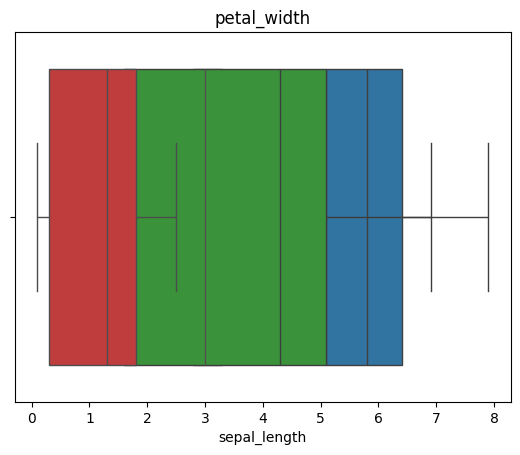

In [10]:
column = df.select_dtypes(include='number')
for col in column:
    sns.boxplot(data=df,x=col)
    plt.title(col)

# Class Distribution (Balance Check)

<Axes: xlabel='species'>

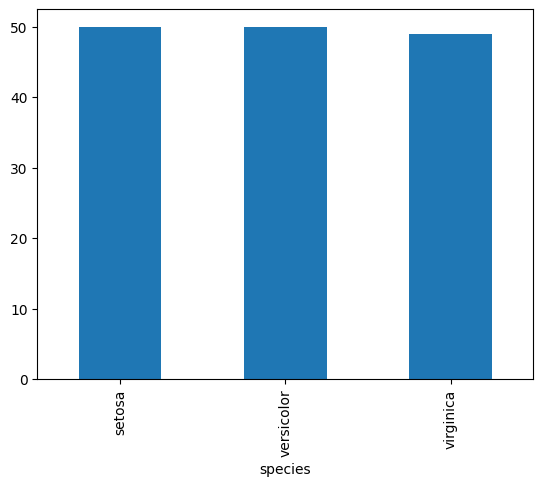

In [11]:
df['species'].value_counts().plot(kind='bar')

**Insight:** The dataset is perfectly balanced, with exactly 50 samples for each of the three species (setosa, versicolor, virginica). This means we don't need to apply any resampling techniques.

# Univariate Analysis (Feature Distributions)

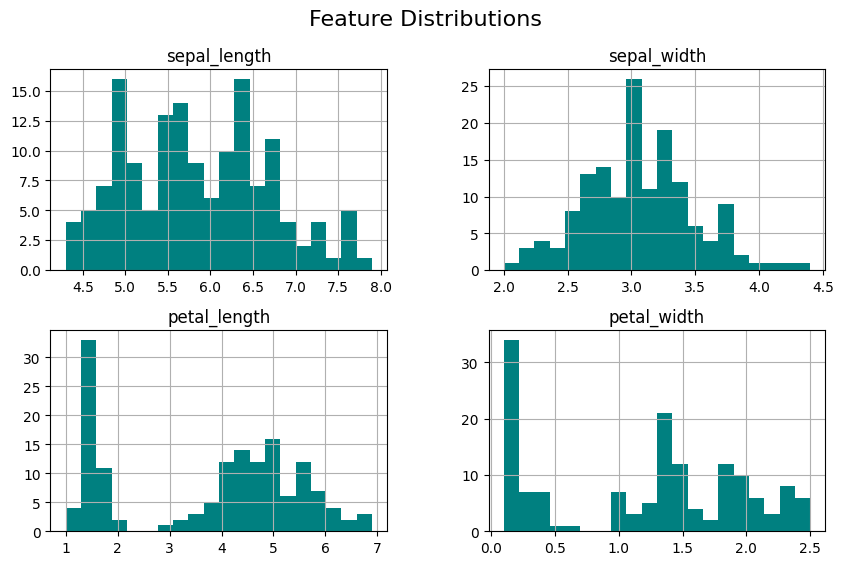

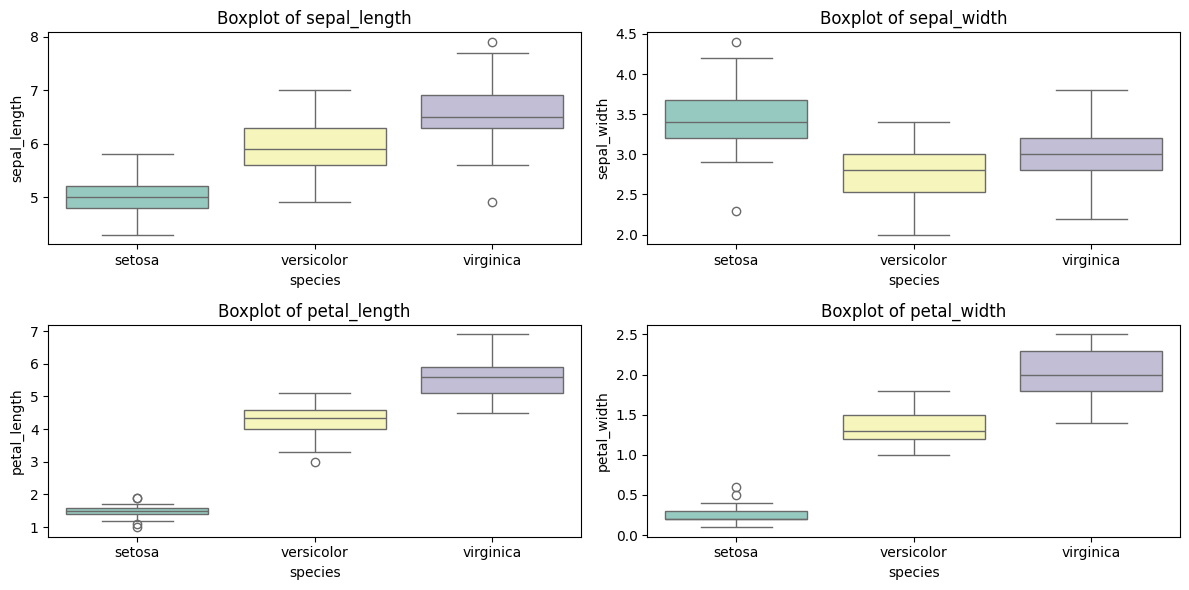

In [12]:
# Histograms to check distributions
df.drop('species', axis=1).hist(figsize=(10, 6), bins=20, color='teal')
plt.suptitle('Feature Distributions', fontsize=16)
plt.show()

# Boxplots to check for outliers
plt.figure(figsize=(12, 6))
for i, col in enumerate(df.columns[:-1]):
    plt.subplot(2, 2, i+1)
    sns.boxplot(data=df, x='species', y=col, palette='Set3',hue='species', legend=False)
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

## 3. Train-Test Split

Before training any machine learning model, we need to split our dataset into two parts:
- **Training Set **: Used to train the models so they can learn the patterns.
- **Testing Set **: Kept completely hidden from the models during training. It is used to evaluate how well the model performs on unseen data.

This prevents **data leakage** and gives us a realistic estimate of the model's performance.

In [13]:
X = df.drop(columns='species',axis=1)
y = df['species']

In [14]:
X.shape

(149, 4)

In [15]:
y.shape

(149,)

In [16]:
le = LabelEncoder()
y = le.fit_transform(y)

In [39]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

## 4. Feature Scaling (StandardScaler)

Feature scaling is a crucial preprocessing step. Algorithms like Logistic Regression are sensitive to the scale of the data. 

We will use `StandardScaler` to normalize our features. It transforms the data such that the mean becomes 0 and the standard deviation becomes 1. 

*Note: To prevent data leakage, the scaler is fitted **only** on the training data and then applied to transform both the training and testing sets.*

In [40]:
scaler = StandardScaler()

In [41]:
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_test)

## 5. Model Training: Logistic Regression

We will train our first benchmark model using **Logistic Regression**. Even though the name says "regression," it is a powerful linear model used for classification tasks. It calculates the probability of an instance belonging to a particular class.

In [42]:
lr = LogisticRegression()
lr.fit(x_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [43]:
y_pred = lr.predict(x_test_scaled)

## 6. Model Training: Decision Tree Classifier

Next, we will train a non-linear model using a **Decision Tree Classifier**. This algorithm splits the data into smaller subsets based on feature thresholds, creating a tree-like structure to make predictions. It is highly interpretable and does not require much data preparation.

In [45]:
dt = DecisionTreeClassifier()
dt.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [46]:
yPred = dt.predict(x_test)

## 7. Model Evaluation & Benchmarking

To compare the performance of both models, we will evaluate them on the test set using the **Classification Report**. 

The key metrics we will look at are:
- **Accuracy**: The overall percentage of correct predictions.
- **Precision**: Of all the instances the model *predicted* as a specific class, how many were actually correct.
- **Recall**: Of all the actual instances of a specific class, how many did the model *successfully find*.
- **F1-Score**: The harmonic mean of Precision and Recall (useful for balanced datasets).

In [47]:
#loLogisticRegression score
print('Accuracy of LR:',accuracy_score(y_test,y_pred))
print('Precision of LR:',precision_score(y_test,y_pred,average='macro'))
print('Recall of LR:',recall_score(y_test,y_pred,average='macro'))
print('f1 score of LR:',f1_score(y_test,y_pred,average='weighted'))
print('confusion matrix:',confusion_matrix(y_test,y_pred))
print('classification report:',classification_report(y_test,y_pred))

Accuracy of LR: 0.9666666666666667
Precision of LR: 0.9666666666666667
Recall of LR: 0.9696969696969697
f1 score of LR: 0.966750208855472
confusion matrix: [[10  0  0]
 [ 0  9  0]
 [ 0  1 10]]
classification report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      1.00      0.95         9
           2       1.00      0.91      0.95        11

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [48]:
#DecisionTreeClassifier score 
print('Accuracy of Decisiontree:',accuracy_score(y_test,yPred))
print('Precision of DecisionTree:',precision_score(y_test,yPred,average='macro'))
print('Recall of DecisionTree:',recall_score(y_test,yPred,average='macro'))
print('f1 score of DecisionTree:',f1_score(y_test,yPred,average='weighted'))
print('confusion matrix:',confusion_matrix(y_test,yPred))
print('classification report:',classification_report(y_test,yPred))

Accuracy of Decisiontree: 1.0
Precision of DecisionTree: 1.0
Recall of DecisionTree: 1.0
f1 score of DecisionTree: 1.0
confusion matrix: [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
classification report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



## 8. Confusion Matrix Visualization (Using ConfusionMatrixDisplay)

To evaluate our models, we use Scikit-Learn's built-in `ConfusionMatrixDisplay`. Unlike manual heatmaps, this utility automatically handles formatting, color mapping, and axis labeling.

For our 3-class problem, the matrix will be 3x3:
- **Diagonal elements** represent correct predictions.
- **Off-diagonal elements** show where the model misclassified (e.g., predicting Versicolor when the actual label was Virginica).

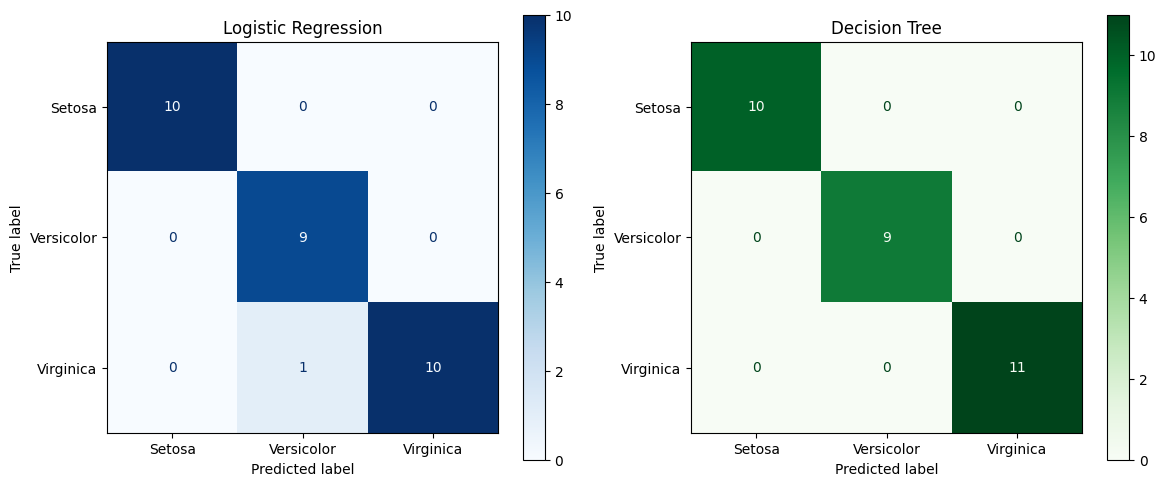

In [49]:
class_names = ['Setosa', 'Versicolor', 'Virginica']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
#1.LogisticRegression cconfusion_matrix
ConfusionMatrixDisplay.from_predictions(y_test,y_pred, display_labels=class_names, cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression')

# 2. Decision Tree Confusion Matrix

ConfusionMatrixDisplay.from_predictions(y_test,yPred,display_labels=class_names, cmap='Greens', ax=axes[1])
axes[1].set_title('Decision Tree')

plt.tight_layout()
plt.show()

## 9. Decision Boundary Visualization

To understand how our models are separating the classes, we plot the decision boundaries. Since our dataset has 4 features, visualizing a 4-dimensional space is impossible for humans. 

Therefore, we train the models on just **two highly correlated features: Petal Length and Petal Width**. We then create a 2D meshgrid and plot the contour regions where the model predicts Setosa, Versicolor, or Virginica. This visually demonstrates how Logistic Regression (linear boundary) differs from Decision Tree (orthogonal/rectangular boundary).

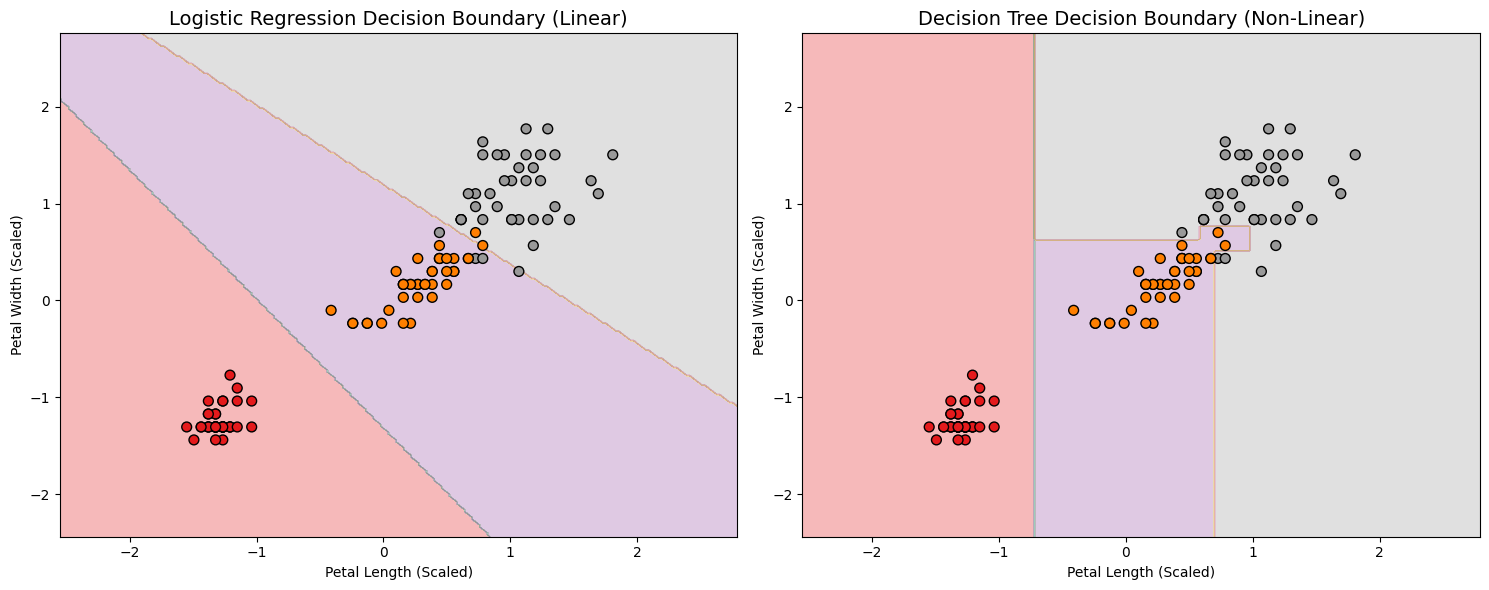

In [50]:
X_2d = df[['petal_length', 'petal_width']]
y_2d = y # Aapka encoded target variable

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d, y_2d, test_size=0.2, random_state=42)

# 3. Scaling
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

lr_2d = LogisticRegression()
dt_2d = DecisionTreeClassifier(random_state=42)

lr_2d.fit(X_train_2d_scaled, y_train_2d)
dt_2d.fit(X_train_2d_scaled, y_train_2d)

x_min, x_max = X_train_2d_scaled[:, 0].min() - 1, X_train_2d_scaled[:, 0].max() + 1
y_min, y_max = X_train_2d_scaled[:, 1].min() - 1, X_train_2d_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# 6. Plotting function
def plot_decision_boundary(model, title, ax):
    # Predict for every point in the meshgrid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Contour plot (background colors)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='Set1')
    
    # Scatter plot (actual data points)
    scatter = ax.scatter(X_train_2d_scaled[:, 0], X_train_2d_scaled[:, 1], 
                         c=y_train_2d, cmap='Set1', edgecolors='k', s=50)
    
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Petal Length (Scaled)')
    ax.set_ylabel('Petal Width (Scaled)')

# Figure create karein
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot boundaries
plot_decision_boundary(lr_2d, 'Logistic Regression Decision Boundary (Linear)', axes[0])
plot_decision_boundary(dt_2d, 'Decision Tree Decision Boundary (Non-Linear)', axes[1])

plt.tight_layout()
plt.show()